In [ ]:
#creating a dataset

import pandas as pd

data = {
    'StudyHours': [2, 5, 8, 3, 7, 1, 6, 4, 9, 2, 5, 6, 1, 3, 8, 7, 4, 9, 10, 2],
    'Attendence': [60, 80, 90, 70, 85, 50, 78, 65, 95, 55, 76, 88, 40, 60, 92, 84, 66, 97, 99, 53],
    'PastScore':[40, 60, 75, 50, 70, 30, 68, 55, 80, 35, 65, 72, 25, 45, 78, 69, 58, 85, 90, 32],
    'Internet': ['Yes','No','No','No','Yes','No','No','No','Yes','Yes','Yes','No','Yes','yes','Yes','No','Yes','No','Yes','No'],
    'Passed' : ['Yes','No','Yes','Yes','Yes','No','NO','No','Yes','No','No','No','Yes','No','Yes','No','Yes','No','Yes','No']
}

df = pd.DataFrame(data)

In [ ]:
#Analysing the dataset

print("Dataset Shape")
print(f'Rows : {df.shape[0]}, Columns : {df.shape[1]}')

print("Data Set Info")
print(df.info())

print("Summary Statistics")
print(df.describe(include ='all'))

print("Missing Values")
print(df.isnull().sum())

Dataset Shape
Rows : 20, Columns : 5
Data Set Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   StudyHours  20 non-null     int64 
 1   Attendence  20 non-null     int64 
 2   PastScore   20 non-null     int64 
 3   Internet    20 non-null     object
 4   Passed      20 non-null     object
dtypes: int64(3), object(2)
memory usage: 932.0+ bytes
None
Summary Statistics
        StudyHours  Attendence  PastScore Internet Passed
count    20.000000   20.000000   20.00000       20     20
unique         NaN         NaN        NaN        3      3
top            NaN         NaN        NaN       No     No
freq           NaN         NaN        NaN       10     10
mean      5.100000   74.150000   59.10000      NaN    NaN
std       2.845125   17.372922   19.41215      NaN    NaN
min       1.000000   40.000000   25.00000      NaN    NaN
25%       2.750000   60.

In [8]:
# Encoding

from sklearn.preprocessing import LabelEncoder

df_label = df.copy()
le = LabelEncoder()

df_label['Internet_Encoded'] = le.fit_transform(df_label['Internet'])
df_label['Passed_Encoded']   = le.fit_transform(df_label['Passed'])



print(df_label[['Internet','Internet_Encoded']].head())
print('\n\n')
print(df_label[['Passed','Passed_Encoded']].head())





  Internet  Internet_Encoded
0      Yes                 1
1       No                 0
2       No                 0
3       No                 0
4      Yes                 1



  Passed  Passed_Encoded
0    Yes               2
1     No               1
2    Yes               2
3    Yes               2
4    Yes               2


Classification Report
              precision    recall  f1-score   support

          No       0.00      0.00      0.00       3.0
         Yes       0.00      0.00      0.00       1.0

    accuracy                           0.00       4.0
   macro avg       0.00      0.00      0.00       4.0
weighted avg       0.00      0.00      0.00       4.0



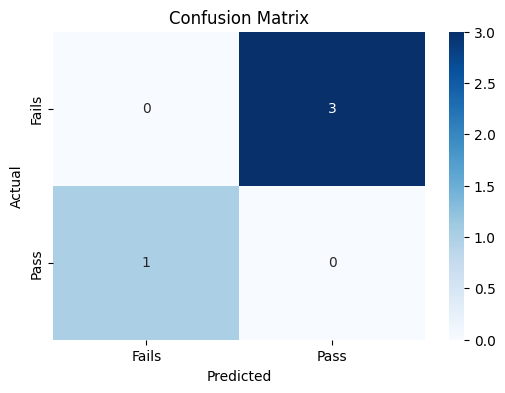

------Predict Your Result------
Prediction Based On input : Fail 


C:\Users\shima\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [13]:
#feature scaling
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report , confusion_matrix
from sklearn.model_selection import train_test_split

features = ['StudyHours', 'Attendence', 'PastScore']
scaler = StandardScaler()
df_label[features] = scaler.fit_transform(df[features])
X = df_label[features]
y = df_label['Passed']
X_train , X_test , y_train , y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train , y_train)
y_pred = model.predict(X_test)

print("Classification Report")
print(classification_report(y_test,y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize = (6,4))
sns.heatmap(conf_matrix , annot = True , fmt ="d" ,cmap="Blues",xticklabels=["Fails","Pass"],yticklabels=['Fails','Pass'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print("------Predict Your Result------")
try:
    study_hours = float(int(input("Enter Study Hours: ")))
    attendence = float(int(input("Enter Attendence: ")))
    Past_Score= float(int(input("Enter Past Score: ")))

    user_input_df = pd.DataFrame([{
        'StudyHours': study_hours,
        'Attendence': attendence,
        'PastScore': Past_Score
    }])

    user_input_scaled =scaler.transform(user_input_df)

    prediction = model.predict(user_input_scaled)[0]
    result = "Pass" if prediction == 1 else "Fail"
    print(f"Prediction Based On input : {result} ")
except Exception as e:
    print("An error occured ", e)
    



        

      